# Qiskitデモ：一般的な測定

Quantum Tokyoでは3回にわたって一般的な測定（「測定の数学的定式化」、「ナイマルクの定理」、「量子状態の識別とトモグラフィー」）の数学的側面を扱ってきました。

今回は補講として、それらのテーマをQiskitで実装して振り返っていきます。測定とその対象として、正四面体状態を扱います。正四面体状態の一般測定、量子状態識別、量子状態トモグラフィーを実装します。

## 0. 準備
今回はqiskit-communityのパッケージの`povm-toolbox`（[ドキュメント](https://qiskit-community.github.io/povm-toolbox/)）を用います。名前の通りPOVM、すなわち一般測定に特化したパッケージになっています。まずはこのパッケージをインストールしてみましょう

In [ ]:
%pip install povm-toolbox qiskit-aer

###  射影測定と一般測定
#### 射影測定

射影行列の集合で表され、各要素の和が恒等行列。
$$
\left\{\Pi_0, \dots ,\Pi_{m-1} \right\},\ such \ that \ \sum_{i=0}^{m-1} \Pi_i = \mathbb{I}
$$

Qiskitの`QuantumCircuit.measurement()`は射影測定に分類されます。測定結果$i$を得られる確率と測定後の応対を記述します。

#### 一般測定(POVM)
半正定値行列の集合で表され、各要素の和が恒等行列。
$$
\left\{E_0, \dots , E_{m-1} \right\},\ such \ that \ \sum_{i=0}^{m-1} E_i = \mathbb{I}
$$


| | 射影測定 | 一般測定 |
|-----|-----|-----|
|行列|射影行列|半正定値行列|
|測定確率 $P(i)$| $\text{Tr}(\Pi_i \rho)$ |$\text{Tr}(E_i \rho)$|
|状態| $\frac{\Pi_i \rho \Pi_i}{\text{Tr}(\Pi_i \rho \Pi_i)}$ | 記述しない |

### 正四面体状態

今回の実装で取り扱う正四面体状態の復習です。正四面体状態は次の4つの状態ベクトル、
$$ \begin{aligned} |\psi_0\rangle &= |0\rangle, \\[4pt] |\psi_1\rangle &= \sqrt{\frac{1}{3}}\,|0\rangle + \sqrt{\frac{2}{3}}\,|1\rangle, \\[4pt] |\psi_2\rangle &= \sqrt{\frac{1}{3}}\,|0\rangle + \sqrt{\frac{2}{3}}\,e^{2\pi i/3}|1\rangle, \\[4pt] |\psi_3\rangle &= \sqrt{\frac{1}{3}}\,|0\rangle + \sqrt{\frac{2}{3}}\,e^{-2\pi i/3}|1\rangle. \end{aligned} $$

からなり、1量子ビットのブロッホ球上で、それらのベクトルを結ぶと正四面体を形成することからそう呼ばれています。

今回のデモに必要なパッケージをインストールします

In [2]:
from qiskit import QuantumCircuit
from qiskit.visualization.bloch import Bloch
from povm_toolbox.library import DilationMeasurements
from povm_toolbox.post_processor import POVMPostProcessor
from povm_toolbox.sampler import POVMSampler
from qiskit_ibm_runtime.executor_sampler import Sampler as RuntimeSampler
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, Operator, DensityMatrix, SparsePauliOp, Pauli
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService

import numpy as np
import pandas as pd
import cvxpy as cp
from IPython.display import display

## 1. 正四面体状態測定
まずは正四面体状態を定義します。今回は`u`ゲートを使って状態準備します。[`u`ゲート](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.UGate) は
$$ U(\theta,\phi,\lambda) = \begin{pmatrix} \cos\left(\frac{\theta}{2}\right) & -e^{i\lambda}\sin\left(\frac{\theta}{2}\right) \\[4pt] e^{i\phi}\sin\left(\frac{\theta}{2}\right) & e^{i(\phi+\lambda)}\cos\left(\frac{\theta}{2}\right) \end{pmatrix} $$
と表されます。

In [3]:
theta = 2 * np.arccos(np.sqrt(1.0/3.0))
phi = 2 * np.pi / 3

#psi_0
psi_0 = QuantumCircuit(1)

#psi_1
psi_1 = QuantumCircuit(1)
psi_1.u(theta, 0, 0, 0)

#psi_2
psi_2 = QuantumCircuit(1)
psi_2.u(theta, phi, 0, 0)

#psi_3
psi_3 = QuantumCircuit(1)
psi_3.u(theta, -phi, 0, 0)

circuits = [psi_0, psi_1, psi_2, psi_3]

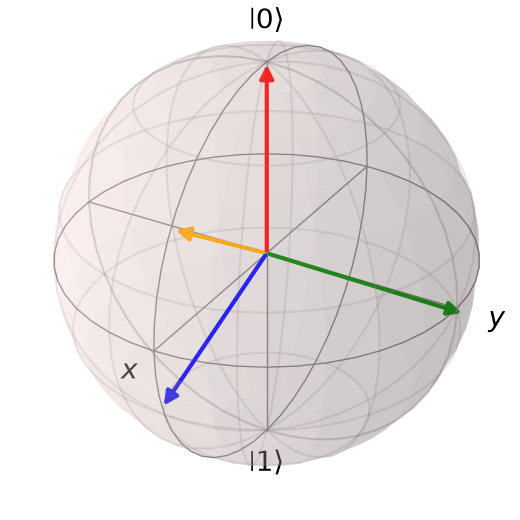

In [5]:
statevectors = [
    Statevector.from_instruction(circuit)
    for circuit in circuits
]


def statevector_to_bloch(state: Statevector) -> np.ndarray:
    return np.array(
        [
            np.real(state.expectation_value(Pauli("X"))),
            np.real(state.expectation_value(Pauli("Y"))),
            np.real(state.expectation_value(Pauli("Z"))),
        ],
        dtype=float,
    )


bloch_vectors = [
    statevector_to_bloch(state)
    for state in statevectors
]


bloch = Bloch()
bloch.add_vectors(bloch_vectors)

bloch.vector_color = ["red", "blue", "green", "orange"]
bloch.vector_width = 3
bloch.title = "Tetrahedral states"

bloch.show()

この4状態を普段私たちが使う量子回路で一般測定を実装することを考えます。正四面体状態は1量子ビットですが、状態が4つあるため、1量子ビットの射影測定では4つの状態を識別することができません。そこで**ナイマルクの定理**を使います。ナイマルクの定理とは、任意の一般測定は、より大きなヒルベルト空間では射影測定として扱うことができる、という定理です。

なので次元が$2$のヒルベルト空間上にある正四面体状態を、次元が$2^2$のヒルベルト空間に拡張して、一般測定を実装します。`povm-toolbox`には[`DilationMeasurements`](https://qiskit-community.github.io/povm-toolbox/stubs/povm_toolbox.library.DilationMeasurements.html#povm_toolbox.library.DilationMeasurements)関数が、このことを実装しています

In [ ]:
sic_parameters = np.array(
    [
        0.75,
        0.30408673,
        0.375,
        0.40678524,
        0.32509973,
        0.25000035,
        0.49999321,
        0.83333313,
    ]
)

measurement = DilationMeasurements(
    num_qubits=1,
    parameters=sic_parameters,
    insert_barriers=True,
)

sim = AerSimulator()
# 実機で実行する場合は次の行のコメントアウトを解除してください
# service = QiskitRuntimeService()
# backend = service.least_busy(operational=True)
# pm = generate_preset_pass_manager(target=backend.target, optimization_level=3)
# isa_circs = [pm.run(circuit) for circuit in circuits]

# はじめに標準的なサンプラーを呼び出します
runtime_sampler = RuntimeSampler(mode=sim)
# 実機で実行する場合は次の行のコメントアウトを解除してください
# runtime_sampler = RuntimeSampler(mode=backend)

# 次にPOVMサンプラーを呼び出します。これは標準的なサンプラーを引数に取りまzす
povm_sampler = POVMSampler(runtime_sampler)

# 定義したPOVMを指定してジョブを提出します。どの回路を測定するか、何ショット実行するかもここで指定できます。
job = povm_sampler.run(circuits, shots=10000, povm=measurement)
# 実機で実行する場合は次の行のコメントアウトを解除してください
# job = povm_sampler.run(circuits, shots=10000, povm=measurement, pass_manager=pm)

実行した結果を理論的に得られる値と比較しましょう。理論的にはPOVM要素と入力状態が定められた時、得られる確率$p(j=\text{outcome}|i=\text{input state})$は

$$ p({j|i}) = \operatorname{Tr}\!\left( E_j |\psi_i\rangle\langle\psi_i| \right) = \frac{1}{2} \left|\langle\psi_j|\psi_i\rangle\right|^2. 
$$ 

$$
p({j|i}) = \begin{cases} \frac{1}{2} & j=i, \\[2pt] \frac{1}{6} & j\neq i. \end{cases}
$$
です。これを確かめましょう

In [ ]:
results = job.result()

rows = []
theory_matrix = np.zeros((4, 4))
simulation_matrix = np.zeros((4, 4))

for i, circuit in enumerate(circuits):
    pub_result = results[i]

    # 状態の密度行列
    state = Statevector.from_instruction(circuit)
    rho = Operator(np.outer(state.data, state.data.conj()))

    povm = pub_result.metadata.povm_implementation.definition()
    counts = pub_result.get_counts()


    shots = sum(counts.values())


    for j in range(4):
        outcome = (j,)  #

        p_theory = float(
            povm.analysis(rho, frame_op_idx=outcome)
        )

        count = counts.get(outcome, 0)
        p_sim = count / shots

        theory_matrix[i, j] = p_theory
        simulation_matrix[i, j] = p_sim

        rows.append(
            {
                "入力状態": f"psi_{i}",
                "POVM要素": j,
                "理論的確率": p_theory,
                "実測確率": p_sim,
            }
        )

comparison = pd.DataFrame(rows)

display(
    comparison.style
    .format({
        "理論的確率": "{:.6f}",
        "実測確率": "{:.6f}",
    })
    .set_properties(**{
        "text-align": "right",
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [("text-align", "right")],
        }
    ])
    .hide(axis="index")
)

入力状態,POVM要素,理論的確率,実測確率
psi_0,0,0.500000,0.500100
psi_0,1,0.166667,0.168000
psi_0,2,0.166667,0.164000
psi_0,3,0.166667,0.167900
psi_1,0,0.166667,0.168500
psi_1,1,0.500000,0.494700
psi_1,2,0.166667,0.170700
psi_1,3,0.166667,0.166100
psi_2,0,0.166667,0.161600
psi_2,1,0.166667,0.173800


## 2. 量子状態識別

前章のデモでは正四面体測定のPOVM要素$E_i$が与えられた状態で測定を行いました。今度は最初にPOVM要素$E_i$が与えられていない状態で、正四面体状態を識別する成功確率を最大化するようなPOVM要素$E_i$を求める、量子状態識別を本章で取り扱います。量子状態識別は、次の制約条件を満たしながら、目的関数を最大化する最適化問題として扱うことができます

$$ \begin{aligned} \underset{\{E_i\}}{\operatorname{maximize}} \quad & \sum_i p_i\,\operatorname{Tr}(E_i\rho_i) \\[6pt] \operatorname{制約条件} \quad & E_i \geq 0 \quad \text{for all } i, \\ & \sum_i E_i = \mathbb{I}. \end{aligned} $$

今回は`cvxpy`という凸最適化ソルバーを使って最適化を行います。

In [45]:
def optimize_discrimination(rhos, priors):
    """既知の状態と事前確率から、最小誤り識別のPOVMを求める。"""
    rhos = [np.asarray(rho, dtype=complex) for rho in rhos]
    priors = np.asarray(priors, dtype=float)

    m = len(rhos)
    d = rhos[0].shape[0]

    # 最適化変数：m個のd×dエルミート行列
    E = [
        cp.Variable((d, d), hermitian=True)
        for _ in range(m)
    ]

    # 制約：E_i >= 0（半正定値）、sum_i E_i = I
    constraints = [Ei >> 0 for Ei in E]
    constraints.append(sum(E) == np.eye(d))

    # 目的関数：平均識別成功率
    success = sum(
        priors[i] * cp.real(cp.trace(E[i] @ rhos[i]))
        for i in range(m)
    )

    problem = cp.Problem(cp.Maximize(success), constraints)
    problem.solve(
        solver=cp.SCS,
        eps=1e-8,
        max_iters=100_000,
    )

    if problem.status not in ("optimal", "optimal_inaccurate"):
        raise RuntimeError(f"最適化に失敗しました: {problem.status}")

    return [Ei.value for Ei in E], float(problem.value), problem.status

In [47]:
#正四面体状態（ベクトル形式）
psis = np.array([
    [1, 0],
    [np.sqrt(1 / 3), np.sqrt(2 / 3)],
    [np.sqrt(1 / 3), np.sqrt(2 / 3) * np.exp(2j * np.pi / 3)],
    [np.sqrt(1 / 3), np.sqrt(2 / 3) * np.exp(-2j * np.pi / 3)],
], dtype=complex)

# rho_i = |psi_i><psi_i|
rhos = [np.outer(psi, psi.conj()) for psi in psis]

# 各状態が等確率で与えられる（確率の初期値）
priors = np.full(4, 1 / 4)

E_opt, p_success, status = optimize_discrimination(rhos, priors)

np.set_printoptions(precision=6, suppress=True)

print("最適化ステータス:", status)
print("識別成功率:", p_success)

for i, Ei in enumerate(E_opt):
    print(f"\nE_{i} =")
    print(Ei)

# conditional[i, j] = P(outcome i | state j)
conditional = np.array([
    [np.trace(Ei @ rho).real for rho in rhos]
    for Ei in E_opt
])

print("\n条件付き確率 P(outcome i | state j):")
print(conditional)

# 数値解の検証
# 完全性の検証
print("\n完全性の残差:",
      np.linalg.norm(sum(E_opt) - np.eye(2)))
# 半正定値性の検証（非負の固有値）
print("全POVM要素の最小固有値:",
      min(np.linalg.eigvalsh(Ei).min() for Ei in E_opt))

最適化ステータス: optimal
識別成功率: 0.5000000000000002

E_0 =
[[ 0.5+0.j -0. +0.j]
 [-0. -0.j  0. +0.j]]

E_1 =
[[0.166667+0.j 0.235702+0.j]
 [0.235702-0.j 0.333333+0.j]]

E_2 =
[[ 0.166667+0.j       -0.117851-0.204124j]
 [-0.117851+0.204124j  0.333333+0.j      ]]

E_3 =
[[ 0.166667+0.j       -0.117851+0.204124j]
 [-0.117851-0.204124j  0.333333+0.j      ]]

条件付き確率 P(outcome i | state j):
[[0.5      0.166667 0.166667 0.166667]
 [0.166667 0.5      0.166667 0.166667]
 [0.166667 0.166667 0.5      0.166667]
 [0.166667 0.166667 0.166667 0.5     ]]

完全性の残差: 1.5045723833145274e-15
全POVM要素の最小固有値: -8.619648205075867e-16


## 3. 量子状態トモグラフィー

量子状態トモグラフィーは未知の量子状態$\rho$を知りたいときに用いる手法です。推定値$\hat{\rho}$は、同じヒルベルト次元数を持つ複数のグループに分け、そのそれぞれに対して物理量の測定を行います。量子ビット系の場合は、ブロッホ球上表示で
$$
\rho = \frac{1}{2}(\mathbb{I} + \sum_{i=x, y, z} s_i \sigma_i)
$$

とかけるので、ブロッホベクトル$s_i$がわかれば、$\rho$が求まります。ここで

$$
s_i = \langle \sigma_i \rangle　\ \text{for all} \ i
$$

であることを思いですと、推定値$\hat{\rho}$は、各パウリ演算子の期待値より導出できます。

量子状態トモグラフィーは推定に用いるショット数$N$を、$ N \rightarrow \infty $で $\hat{\rho} \rightarrow \rho$に収束することが知られています

In [ ]:

result = job.result()
for i in range(len(result)):
    # 
    processor = POVMPostProcessor(result[i])

    # X・Y・Z の期待値計算
    expectations = {}
    for label in ("X", "Y", "Z"):
        mean, uncertainty = processor.get_expectation_value(
            SparsePauliOp(label)
        )
        expectations[label] = np.asarray(mean).item()

    # 密度演算子のブロッホ球表現
    rho_matrix = np.eye(2, dtype=complex)
    for label in ("X", "Y", "Z"):
        rho_matrix += (
            expectations[label] * SparsePauliOp(label).to_matrix()
        )
    rho_matrix /= 2

    rho_est = DensityMatrix(rho_matrix)
    print("密度行列の推定値:")
    print(rho_est.data)
    print("固有値:", np.linalg.eigvalsh(rho_est.data))

密度行列の推定値:
[[ 1.0002  +0.j        0.002899+0.004777j]
 [ 0.002899-0.004777j -0.0002  +0.j      ]]
固有値: [-0.000231  1.000231]
密度行列の推定値:
[[0.337   +0.j       0.461458-0.005634j]
 [0.461458+0.005634j 0.663   +0.j      ]]
固有値: [0.010567 0.989433]
密度行列の推定値:
[[ 0.323193+0.j       -0.224148-0.410045j]
 [-0.224148+0.410045j  0.676807+0.j      ]]
固有値: [0.000361 0.999639]
密度行列の推定値:
[[ 0.322007+0.j       -0.221825+0.408452j]
 [-0.221825-0.408452j  0.677993+0.j      ]]
固有値: [0.002284 0.997716]
